# Praktikum 5 - Klasifikasi Citra Siang dan Malam


## 1. Import library dan path dataset


In [1]:
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

# Direktori gambar training dan test
train_dir = 'images/training/'
test_dir = 'images/test/'


## 2. Load dataset gambar


In [2]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = [d for d in p.glob('*') if d.is_dir()]
    img_list = []

    for d in dirs:
        label = d.name
        for file in d.glob('*.jpg'):
            img = mpimg.imread(file)
            if img is not None:
                img_list.append((img, label))
    
    return img_list

# Load data gambar training
train_img = load_dataset(train_dir)
print(f'Jumlah gambar training: {len(train_img)}')


Jumlah gambar training: 240


## Cek data pertama


In [3]:
print('Tipe data elemen pertama:', type(train_img[0]))
print('Label gambar pertama:', train_img[0][1])
print('Bentuk array gambar pertama:', train_img[0][0].shape)


Tipe data elemen pertama: <class 'tuple'>
Label gambar pertama: day
Bentuk array gambar pertama: (458, 800, 3)


## Cek resolusi gambar asli


In [4]:
pick_random = np.random.randint(0, len(train_img))
print(f'Indeks gambar: {pick_random}')
print('Dimensi (tinggi, lebar, kanal):', train_img[pick_random][0].shape)


Indeks gambar: 123
Dimensi (tinggi, lebar, kanal): (737, 1024, 3)


## Fungsi visualisasi acak


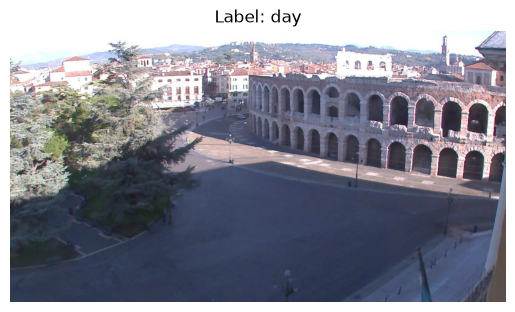

Bentuk gambar: (700, 1280, 3)
Label: day


In [5]:
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))
    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    
    plt.imshow(img)
    plt.title(f'Label: {label}')
    plt.axis('off')
    plt.show()
    print(f'Bentuk gambar: {img.shape}')
    print(f'Label: {label}')

random_img_viz(train_img)


## 3. Preprocessing (resize 1100x600 dan encode label)


In [6]:
def standarized_input(image):
    # Standarisasi resolusi ke lebar 1100 dan tinggi 600
    std_img = cv2.resize(image, (1100, 600))
    return std_img

def label_encoder(label):
    # Encode label: day = 1, night = 0
    if label == 'day' or label == 1:
        return 1
    return 0

def preprocess(img_list):
    std_img_list = []
    for item in img_list:
        image = item[0]
        label = item[1]
        
        std_img = standarized_input(image)
        img_label = label_encoder(label)
        std_img_list.append((std_img, img_label))
    return std_img_list

train_std_img_list = preprocess(train_img)
print(f'Total gambar yang sudah distandarisasi: {len(train_std_img_list)}')


Total gambar yang sudah distandarisasi: 240


## Cek resolusi setelah standarisasi


In [7]:
pick_random = np.random.randint(0, len(train_std_img_list))
print(f'Gambar indeks {pick_random}')
print('Ukuran seragam:', train_std_img_list[pick_random][0].shape)


Gambar indeks 74
Ukuran seragam: (600, 1100, 3)


## 4. Ekstraksi fitur rata-rata kecerahan (HSV)


Gambar indeks 119
Nilai rata-rata kecerahan: 142.1082


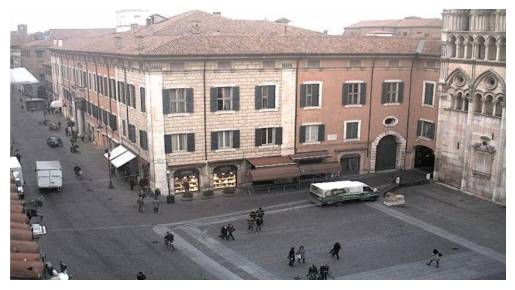

In [8]:
def avg_brightness(image):
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    sum_brightness = np.sum(img_hsv[:, :, 2])
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area
    return avg

# Pengecekan pada satu gambar acak
rand_img = np.random.randint(0, len(train_std_img_list))
feature_img = train_std_img_list[rand_img][0]
avg_val = avg_brightness(feature_img)

print(f'Gambar indeks {rand_img}')
print(f'Nilai rata-rata kecerahan: {avg_val:.4f}')
plt.imshow(feature_img)
plt.axis('off')
plt.show()


## 5. Klasifikasi dengan threshold


Gambar indeks 76
Label sebenarnya : 1
Label prediksi   : 1


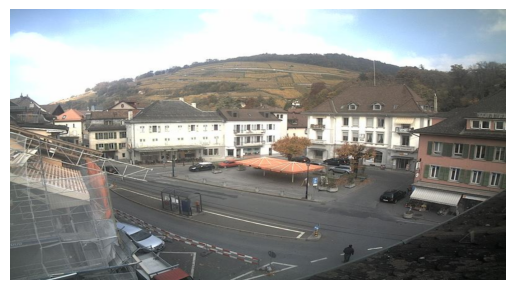

In [9]:
def predict_label(img, threshold):
    avg = avg_brightness(img)
    if avg > threshold:
        return 1
    return 0

rand_img = np.random.randint(0, len(train_std_img_list))
pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

print(f'Gambar indeks {rand_img}')
print(f'Label sebenarnya : {train_std_img_list[rand_img][1]}')
print(f'Label prediksi   : {pred}')
plt.imshow(train_std_img_list[rand_img][0])
plt.axis('off')
plt.show()


## 6. Evaluasi akurasi threshold manual


In [10]:
def evaluate(img_list, threshold):
    miss_labels = []
    for file in img_list:
        img = file[0]
        label = file[1]
        pred_label = predict_label(img, threshold)
        if pred_label != label:
            miss_labels.append((img, pred_label, label))
    
    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img
    print(f'Accuracy: {accuracy:.4f}')
    return accuracy

print('Evaluasi data training (threshold 120):')
evaluate(train_std_img_list, threshold=120)

# Evaluasi pada data testing
test_img = load_dataset(test_dir)
test_std_img_list = preprocess(test_img)

print('Evaluasi data testing (threshold 120):')
evaluate(test_std_img_list, threshold=120)


Evaluasi data training (threshold 120):


Accuracy: 0.8417


Evaluasi data testing (threshold 120):


Accuracy: 0.8688


0.86875

## 7. Ekstraksi fitur untuk SVM


In [11]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []
    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]
        avg_list.append(img_avg)
        labels.append(img_label)
    
    data = np.column_stack((avg_list, labels))
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])
    return df

train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Dimensi tabel fitur train: {train_avg_img.shape}')
train_avg_img.head()


Dimensi tabel fitur train: (240, 2)


,AVG_BRIGHT,LABELS
0,175.092992,1.0
1,192.907867,1.0
2,132.133823,1.0
3,199.749191,1.0
4,109.947203,1.0


In [12]:
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Dimensi tabel fitur test: {test_avg_img.shape}')
test_avg_img.head()


Dimensi tabel fitur test: (160, 2)


,AVG_BRIGHT,LABELS
0,194.228062,1.0
1,157.826662,1.0
2,201.607444,1.0
3,191.237441,1.0
4,188.119652,1.0


## 8. Training SVM RBF


In [13]:
from sklearn.svm import SVC

X_train = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train = train_avg_img.iloc[:, 1]
X_test = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test = test_avg_img.iloc[:, 1]

model = SVC()
model.fit(X_train, y_train)


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


## 9. Evaluasi akurasi SVM


In [14]:
from sklearn.metrics import accuracy_score

y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test : {acc_test}')


Accuracy on train: 0.8583333333333333
Accuracy on test : 0.9
